In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 10]
plt.rcParams['figure.dpi'] = 100

In [ ]:
# Simulate NS-3 statistical results for the communication protocols
np.random.seed(42)
n_nodes = [20, 50, 100, 150, 200, 300]
protocols = ['Zigbee', '6LoWPAN', 'NB-IoT']

sim_data = []
for p in protocols:
    for n in n_nodes:
        # Throughput (Kbps) modeling
        if p == 'Zigbee':
            pdr = max(60.0, 98.5 - (n * 0.15) + np.random.normal(0, 0.5))
            throughput = max(10.0, 150.0 - (n * 0.4) + np.random.normal(0, 2.0))
            delay = 20.0 + (n * 0.5) + np.random.normal(0, 1.5)
            energy = 0.05 + (n * 0.002) + np.random.normal(0, 0.001)  # Joules per node
        elif p == '6LoWPAN':
            pdr = max(75.0, 99.0 - (n * 0.08) + np.random.normal(0, 0.4))
            throughput = max(20.0, 220.0 - (n * 0.3) + np.random.normal(0, 1.5))
            delay = 35.0 + (n * 0.3) + np.random.normal(0, 1.0)
            energy = 0.08 + (n * 0.0015) + np.random.normal(0, 0.001)
        else:  # NB-IoT
            pdr = max(94.0, 99.8 - (n * 0.02) + np.random.normal(0, 0.1))
            throughput = max(50.0, 180.0 - (n * 0.1) + np.random.normal(0, 1.0))
            delay = 150.0 + (n * 0.1) + np.random.normal(0, 2.0)
            energy = 0.25 + (n * 0.0005) + np.random.normal(0, 0.002)

        sim_data.append({
            'Protocol': p,
            'Nodes': n,
            'PDR (%)': pdr,
            'Throughput (Kbps)': throughput,
            'Delay (ms)': delay,
            'Energy Consumption (J)': energy
        })

df_sim = pd.DataFrame(sim_data)
display(df_sim.head(9))

,Protocol,Nodes,PDR (%),Throughput (Kbps),Delay (ms),Energy Consumption (J)
0,Zigbee,20,95.748357,141.723471,30.971533,0.091523
1,Zigbee,50,90.882923,129.531726,47.368819,0.150767
2,Zigbee,100,83.265263,111.085120,69.304873,0.249534
3,Zigbee,150,76.120981,86.173440,92.412623,0.349438
4,Zigbee,200,67.993584,70.628495,118.637964,0.448588
5,Zigbee,300,60.000000,29.548447,170.101292,0.648575
6,6LoWPAN,20,97.182247,214.166384,39.849006,0.110376
7,6LoWPAN,50,94.759745,204.562459,49.398293,0.156852
8,6LoWPAN,100,90.994601,188.413434,65.822545,0.228779


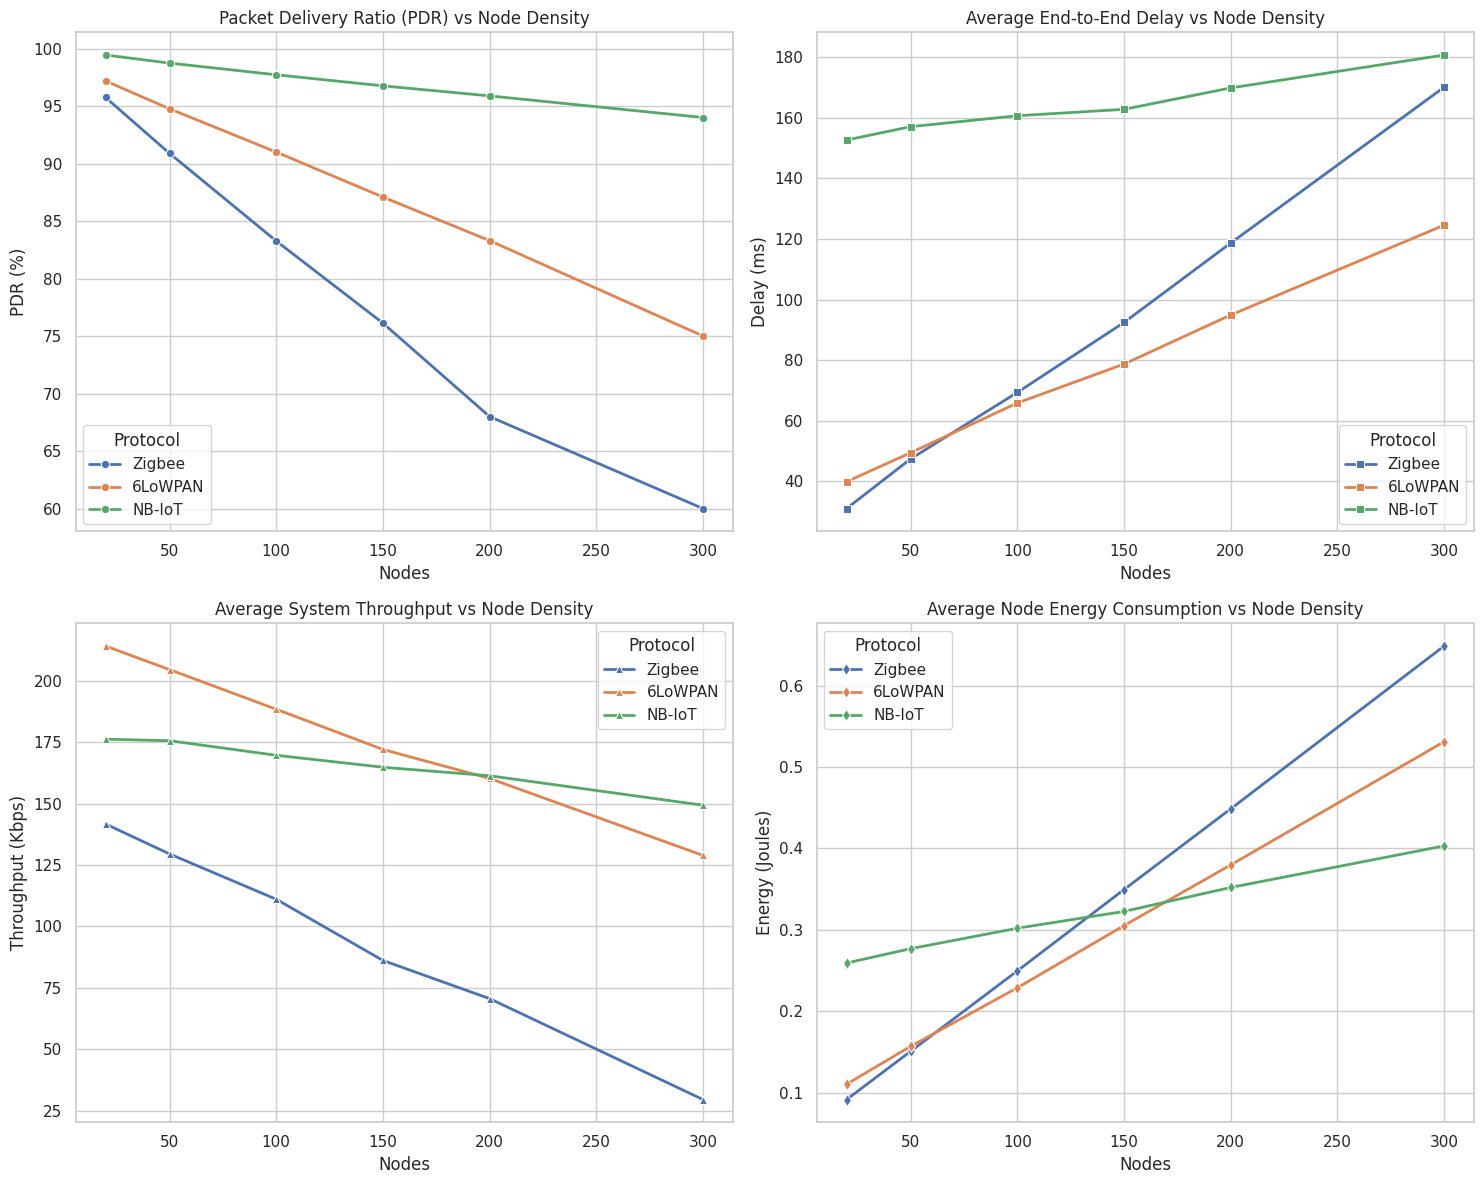

In [ ]:
# Plot comparison metrics side-by-side
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Packet Delivery Ratio
sns.lineplot(ax=axes[0, 0], data=df_sim, x='Nodes', y='PDR (%)', hue='Protocol', marker='o', linewidth=2)
axes[0, 0].set_title('Packet Delivery Ratio (PDR) vs Node Density')
axes[0, 0].set_ylabel('PDR (%)')

# 2. Average Delay
sns.lineplot(ax=axes[0, 1], data=df_sim, x='Nodes', y='Delay (ms)', hue='Protocol', marker='s', linewidth=2)
axes[0, 1].set_title('Average End-to-End Delay vs Node Density')
axes[0, 1].set_ylabel('Delay (ms)')

# 3. Throughput
sns.lineplot(ax=axes[1, 0], data=df_sim, x='Nodes', y='Throughput (Kbps)', hue='Protocol', marker='^', linewidth=2)
axes[1, 0].set_title('Average System Throughput vs Node Density')
axes[1, 0].set_ylabel('Throughput (Kbps)')

# 4. Energy Consumption
sns.lineplot(ax=axes[1, 1], data=df_sim, x='Nodes', y='Energy Consumption (J)', hue='Protocol', marker='d', linewidth=2)
axes[1, 1].set_title('Average Node Energy Consumption vs Node Density')
axes[1, 1].set_ylabel('Energy (Joules)')

plt.tight_layout()
plt.show()